In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

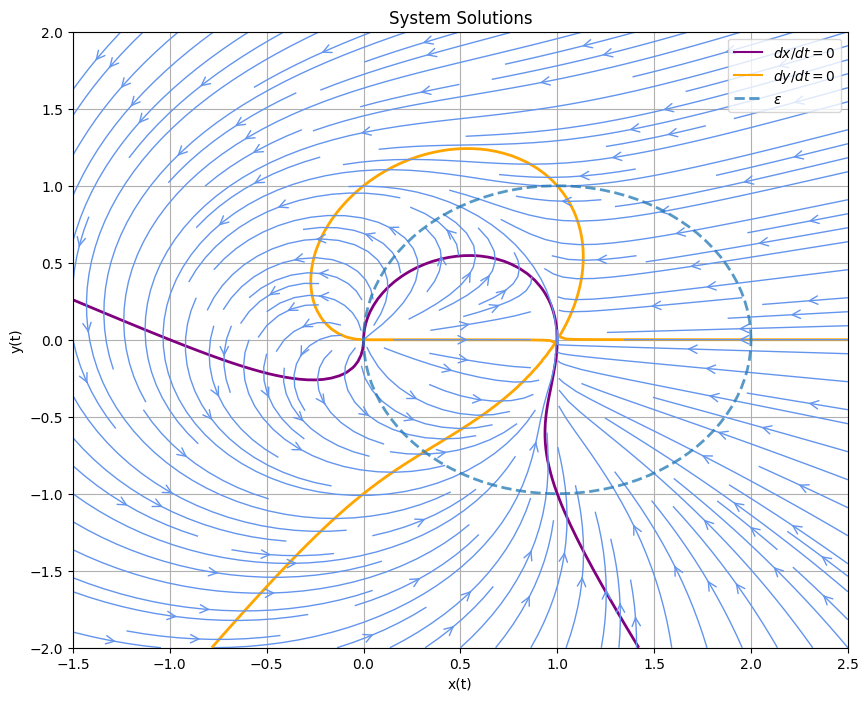

In [ ]:
# ODE system in x, y
def ode_system(t, XY):
  x, y = XY
  xdot = x - np.sqrt(x**2 + y**2) * (x + y) + x * y
  ydot = y + np.sqrt(x**2 + y**2) * (x - y) - x**2
  return [xdot, ydot]

initial_conditions = [(1,0)] # given equilibrium point

t_0 = 0
t_f = 500
times = np.linspace(t_0, t_f, 1000)  # Points where solution is recorded

# numerically solve system
solutions = []
for ic in initial_conditions:
  sol = solve_ivp(ode_system, t_span = (t_0, t_f), y0=ic, t_eval = times, vectorized = True)
  solutions.append(sol)

# create grid of points for vector field and nullcines
x_range = np.linspace(-1.5, 2.5, 100)
y_range = np.linspace(-2, 2, 100)
X,Y = np.meshgrid(x_range, y_range)
DX, DY = ode_system(0, [X,Y])

# plot results
plt.figure(figsize=(10, 8))
for solution in solutions:
  plt.plot(solution.y[0], solution.y[1], linewidth=4, color = "darkslateblue")
# plt.plot([], [], color = "darkslateblue", label = r"$\phi_t(x_0, y_0)$")

# plot nullclines
plt.contour(X, Y, DX, levels=[0], linewidths = 2, colors = "purple")
plt.contour(X, Y, DY, levels=[0], linewidths = 2, colors = "orange")
plt.plot([], [], color = "purple", label = r"$dx/dt=0$")
plt.plot([], [], color = "orange", label = r"$dy/dt=0$")

# plot phase plane
plt.streamplot(X, Y, DX, DY, linewidth=1, color = "cornflowerblue",
              density=1.5, arrowstyle='->', arrowsize=1.5)

theta = np.linspace(0, 2 * np.pi, 100)
epsilon_x = 1 + 1 * np.cos(theta)
epsilon_y = 1 * np.sin(theta)
plt.plot(epsilon_x, epsilon_y, linewidth = 2, alpha = 0.75, linestyle = 'dashed', label = r"$\varepsilon$")

plt.xlabel('x(t)')
plt.xlim(-1.5,2.5)
plt.ylabel('y(t)')
plt.ylim(-2,2)

plt.title('System Solutions')
plt.legend(loc = 'upper right')
plt.grid(True)
plt.show()

### Trying various initial conditions for a vibe check

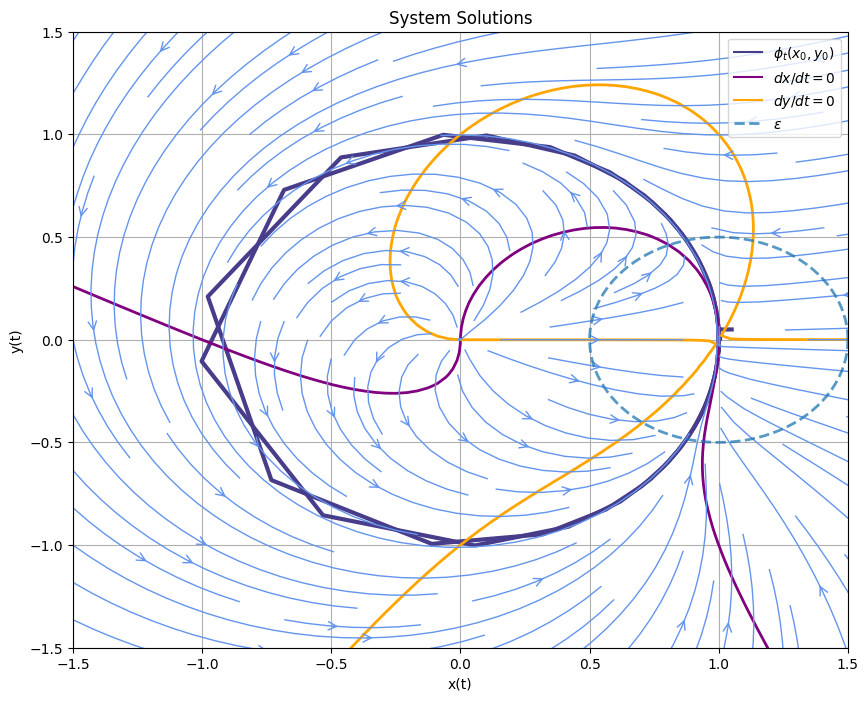

In [ ]:
initial_conditions = [(1.05, 0.05), (1.005, 0.005), (1.0005, 0.0005), (1.00005, 0.00005), (1.00000005, 0.00000005)]

t_0 = 0
t_f = 500
times = np.linspace(t_0, t_f, 1000)  # Points where solution is recorded

# numerically solve system
solutions = []
for ic in initial_conditions:
  sol = solve_ivp(ode_system, t_span = (t_0, t_f), y0=ic, t_eval = times, vectorized = True)
  solutions.append(sol)

# create grid of points for vector field and nullcines
x_range = np.linspace(-1.5, 2.5, 100)
y_range = np.linspace(-2, 2, 100)
X,Y = np.meshgrid(x_range, y_range)
DX, DY = ode_system(0, [X,Y])

# plot results
plt.figure(figsize=(10, 8))
for solution in solutions:
  plt.plot(solution.y[0], solution.y[1], linewidth = 3, color = "darkslateblue")
plt.plot([], [], color = "darkslateblue", label = r"$\phi_t(x_0, y_0)$")

# plot nullclines
plt.contour(X, Y, DX, levels=[0], linewidths = 2, colors = "purple")
plt.contour(X, Y, DY, levels=[0], linewidths = 2, colors = "orange")
plt.plot([], [], color = "purple", label = r"$dx/dt=0$")
plt.plot([], [], color = "orange", label = r"$dy/dt=0$")

# plot phase plane
plt.streamplot(X, Y, DX, DY, linewidth=1, color = "cornflowerblue",
              density=1.5, arrowstyle='->', arrowsize=1.5)

theta = np.linspace(0, 2 * np.pi, 100)
epsilon_x = 1 + 0.5 * np.cos(theta)
epsilon_y = 0.5 * np.sin(theta)
plt.plot(epsilon_x, epsilon_y, linewidth = 2, alpha = 0.75, linestyle = 'dashed', label = r"$\varepsilon$")

plt.xlabel('x(t)')
plt.xlim(-1.5,1.5)
plt.ylabel('y(t)')
plt.ylim(-1.5,1.5)

plt.title('System Solutions')
plt.legend(loc = 'upper right')
plt.grid(True)
plt.show()